# ÉquiAlgo — Rapport d'audit du biais régional

**Question :** le modèle en production accorde une bourse à 48 % des candidat·es des grands centres
et à 27 % des régions éloignées. Quelle part de cet écart vient du mérite, et quelle part vient d'un biais ?

**Constats principaux** (chaque chiffre est recalculé plus bas) :

1. **La cote R n'explique qu'une petite partie de l'écart.** À cote R égale, un dossier des régions éloignées
   a des chances d'octroi nettement plus faibles. Dans le modèle logistique du comité, la pénalité régionale
   équivaut à **≈ 1,5 point de cote R** et explique à elle seule **≈ 80 % de l'écart de 21 points**.
2. **Il y a un deuxième biais : le revenu familial.** À cote R égale, le comité favorise les familles aisées
   (un revenu doublé vaut ≈ 0,9 point de cote R). Or le revenu est plus bas en région (médiane ≈ 52 k$ contre ≈ 69 k$) :
   c'est un canal indirect de la même discrimination.
3. **Les proxys sont presque parfaits.** Le code postal sépare les deux groupes à 100 %, la distance à 99,8 % (AUC).
   Sans aucune colonne géographique, les heures travaillées et le revenu prédisent encore la région (AUC ≈ 0,85).
   Supprimer `region_administrative` ne peut donc pas fonctionner.
4. **Métrique retenue : égalité des chances**, mesurée contre une **estimation du mérite**, pas contre
   `decision_octroi`. Mesurée contre les décisions du comité, l'égalité des chances ne fait que valider la copie du biais.
5. **Reconstruction de l'étalon.** Le mérite défini comme *cote R + crédit pour les heures travaillées* (sans région,
   sans revenu) reproduit l'écart de départ publié par les organisateurs (**0,270**). Les autres hypothèses
   testées ne le reproduisent pas. Les deux groupes ont alors **le même taux de mérite (≈ 40 %)**.

## 1. Données et intégrité

In [1]:
import hashlib, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

from commun import (COULEURS, GRIS, ELOIGNEES, charger, encoder, top_k,
                    ecart_egalite_chances, ecart_parite, style_graphique)
style_graphique()
pd.set_option('display.width', 120)

# Les fichiers sont-ils ceux du manifeste officiel ?
manifeste = {f['path']: f['sha256'] for f in json.load(open('manifest.json'))['files']}
for chemin in ['data/donnees_demandes.csv', 'data/candidats_evaluation.csv']:
    ok = hashlib.sha256(open(chemin, 'rb').read()).hexdigest() == manifeste[chemin]
    print(f'{chemin:35s} sha256 {"OK" if ok else "DIFFERENT"}')

hist, cand = charger()
print(f'\n{len(hist)} dossiers historiques, {len(cand)} candidats a evaluer')
print('Valeurs manquantes :', int(hist.isna().sum().sum()), '/', int(cand.isna().sum().sum()))
print('Identifiants en double :', int(hist.id_candidat.duplicated().sum()),
      '| chevauchement historique/evaluation :', len(set(hist.id_candidat) & set(cand.id_candidat)))

data/donnees_demandes.csv           sha256 OK
data/candidats_evaluation.csv       sha256 OK

10000 dossiers historiques, 4000 candidats a evaluer
Valeurs manquantes : 0 / 0
Identifiants en double : 0 | chevauchement historique/evaluation : 0


## 2. L'écart brut

In [2]:
par_region = (hist.groupby(['groupe', 'region_administrative'])
              .agg(dossiers=('decision_octroi', 'size'),
                   taux_octroi=('decision_octroi', 'mean'),
                   cote_r=('cote_r_equivalent', 'mean'),
                   revenu=('revenu_familial_estime', 'median'),
                   heures=('heures_travail_semaine', 'mean'),
                   distance_km=('distance_domicile_campus_km', 'median'),
                   premiere_gen=('premiere_generation_universitaire', 'mean'))
              .round(3))
display(par_region)

par_groupe = hist.groupby('groupe')['decision_octroi'].mean()
print(f"Taux d'octroi : Centre {par_groupe['Centre']:.1%}  |  Eloignee {par_groupe['Eloignee']:.1%}"
      f"  ->  ecart {par_groupe['Centre'] - par_groupe['Eloignee']:.1%}")
print('Repartition des candidats a evaluer :', cand.groupe.value_counts(normalize=True).round(3).to_dict())

dossiers  taux_octroi  cote_r   revenu  heures  distance_km  premiere_gen
groupe   region_administrative                                                                                   
Centre   Capitale-Nationale                 1999        0.484  27.984  69409.0   8.949         16.7         0.258
         Montreal                           4001        0.483  27.988  69086.0   8.984         17.1         0.268
Eloignee Bas-Saint-Laurent                  1293        0.269  27.296  51731.0  12.954        202.0         0.448
         Cote-Nord                          1178        0.263  27.325  51218.5  13.115        207.7         0.428
         Gaspesie-Iles-de-la-Madeleine      1529        0.284  27.354  51687.0  13.001        204.4         0.453

Taux d'octroi : Centre 48.4%  |  Eloignee 27.3%  ->  ecart 21.1%
Repartition des candidats a evaluer : {'Centre': 0.593, 'Eloignee': 0.407}


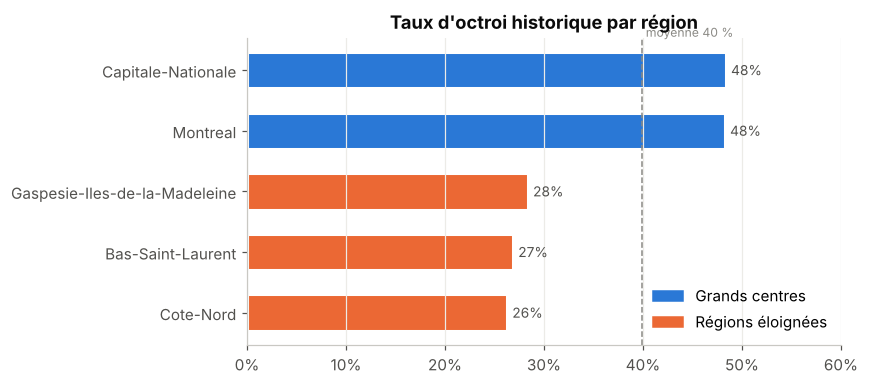

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ordre = par_region.reset_index().sort_values('taux_octroi')
ax.barh(ordre.region_administrative, ordre.taux_octroi, height=0.6,
        color=[COULEURS[g] for g in ordre.groupe], edgecolor='white', linewidth=2)
for y, (t, g) in enumerate(zip(ordre.taux_octroi, ordre.groupe)):
    ax.text(t + 0.005, y, f'{t:.0%}', va='center', fontsize=9, color='#52514e')
ax.axvline(hist.decision_octroi.mean(), color=GRIS, lw=1, ls='--')
ax.text(hist.decision_octroi.mean(), len(ordre) - 0.45, ' moyenne 40 %', color=GRIS, fontsize=8)
ax.set_xlim(0, 0.6); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title("Taux d'octroi historique par région")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS.values()],
          labels=['Grands centres', 'Régions éloignées'], loc='lower right')
plt.tight_layout(); plt.show()

## 3. La cote R explique-t-elle l'écart ?

On compare les taux d'octroi **à cote R égale**. Si le comité ne regardait que la cote R, les deux courbes
se superposeraient.

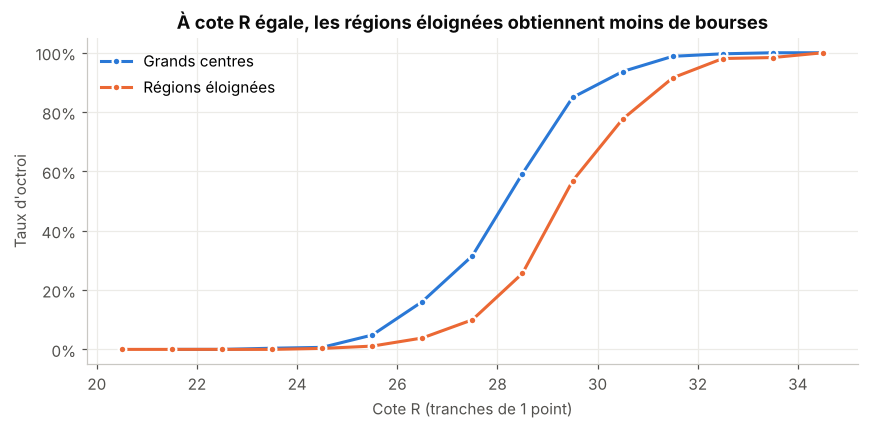

In [4]:
bornes = np.arange(20, 36, 1.0)
hist['tranche_r'] = pd.cut(hist.cote_r_equivalent, bornes)
courbe = hist.groupby(['tranche_r', 'groupe'], observed=True)['decision_octroi'].agg(['mean', 'size']).reset_index()
courbe = courbe[courbe['size'] >= 30]
courbe['milieu'] = courbe.tranche_r.apply(lambda i: i.mid)

fig, ax = plt.subplots(figsize=(8, 4))
for g, nom in [('Centre', 'Grands centres'), ('Eloignee', 'Régions éloignées')]:
    s = courbe[courbe.groupe == g]
    ax.plot(s.milieu, s['mean'], color=COULEURS[g], lw=2, marker='o', ms=5, label=nom,
            markeredgecolor='white', markeredgewidth=1.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Cote R (tranches de 1 point)'); ax.set_ylabel("Taux d'octroi")
ax.set_title("À cote R égale, les régions éloignées obtiennent moins de bourses")
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

### Décomposition : régression logistique des décisions du comité

On modélise `decision_octroi` en fonction de toutes les variables. Pour rendre les coefficients lisibles, on les
convertit en **équivalent points de cote R** (coefficient ÷ coefficient de la cote R).

In [5]:
hist['eloignee'] = (hist.groupe == 'Eloignee').astype(int)
hist['log_revenu'] = np.log(hist.revenu_familial_estime)

formules = {
    'A. cote R seule': 'decision_octroi ~ cote_r_equivalent',
    'B. A + region': 'decision_octroi ~ cote_r_equivalent + eloignee',
    'C. tout sauf region': 'decision_octroi ~ cote_r_equivalent + log_revenu + heures_travail_semaine'
                           ' + distance_domicile_campus_km + premiere_generation_universitaire + C(programme_etudes)',
    'D. tout + region': 'decision_octroi ~ cote_r_equivalent + log_revenu + heures_travail_semaine'
                        ' + distance_domicile_campus_km + premiere_generation_universitaire + C(programme_etudes) + eloignee',
}
modeles = {k: smf.logit(f, hist).fit(disp=0) for k, f in formules.items()}
print(pd.DataFrame({k: {'AIC': m.aic, 'pseudo-R2': m.prsquared} for k, m in modeles.items()}).T.round(3))

m = modeles['D. tout + region']
tableau = pd.DataFrame({'coef': m.params, 'p': m.pvalues,
                        'equiv. points R': m.params / m.params['cote_r_equivalent']}).drop('Intercept')
display(tableau.round(4))

                          AIC  pseudo-R2
A. cote R seule      6382.922      0.526
B. A + region        5918.171      0.561
C. tout sauf region  5419.143      0.599
D. tout + region     5183.218      0.616


,coef,p,equiv. points R
C(programme_etudes)[T.Genie],0.0537,0.6323,0.0388
C(programme_etudes)[T.Sante],0.0642,0.5944,0.0464
C(programme_etudes)[T.Sciences],0.0211,0.8541,0.0152
C(programme_etudes)[T.Sciences sociales],0.0081,0.9440,0.0058
cote_r_equivalent,1.3856,0.0000,1.0000
log_revenu,1.7776,0.0000,1.2829
heures_travail_semaine,0.2020,0.0000,0.1458
distance_domicile_campus_km,0.0011,0.0334,0.0008
premiere_generation_universitaire,-0.0515,0.5018,-0.0372
eloignee,-2.1547,0.0000,-1.5551


**Lecture.**

- **Région éloignée : ≈ −1,5 point de cote R**, très significatif, même après contrôle de toutes les autres variables.
  C'est la partie « inexpliquée » de l'écart.
- **Revenu familial (log) : ≈ +1,3 point R par unité de log**, soit ≈ +0,9 point quand le revenu double. Le comité
  favorise les familles aisées, et le revenu est plus faible en région : c'est un **deuxième canal du biais**.
- **Heures travaillées : ≈ +0,15 point R par heure.** Le comité récompense les étudiant·es qui travaillent
  pendant leurs études. On l'interprète comme un critère de mérite (effort, contrainte de temps), voir section 6.
- **Programme, première génération** : non significatifs une fois la région contrôlée.
- **Distance** : effet propre minime (≈ 0,08 point R par 100 km) une fois la région contrôlée. Elle ne sert
  essentiellement que de proxy de la région.

In [6]:
# Contrefactuel : memes dossiers, on change seulement la region (modele D).
contre = hist.copy()
proba_reelle = m.predict(hist)
contre['eloignee'] = 0
proba_centre = m.predict(contre)
el = hist.eloignee == 1
print(f"Dossiers eloignes - probabilite moyenne d'octroi : {proba_reelle[el].mean():.1%} "
      f"-> {proba_centre[el].mean():.1%} s'ils etaient evalues comme au Centre")

# Decomposition de l'ecart en points de pourcentage
ecart_total = hist.decision_octroi[~el].mean() - hist.decision_octroi[el].mean()
ecart_region = proba_centre[el].mean() - proba_reelle[el].mean()
print(f"Ecart total {ecart_total:.1%} dont {ecart_region:.1%} du a l'effet direct de la region "
      f"({ecart_region / ecart_total:.0%})")

Dossiers eloignes - probabilite moyenne d'octroi : 27.3% -> 44.7% s'ils etaient evalues comme au Centre
Ecart total 21.1% dont 17.4% du a l'effet direct de la region (83%)


## 4. Variables proxys

Une variable est un proxy si elle permet de deviner la région. On mesure l'AUC de chaque variable seule
pour séparer *Centre* et *Éloignée* (0,5 = aucune information, 1,0 = séparation parfaite), puis celle d'un
modèle qui combine toutes les variables non géographiques.

In [7]:
y_groupe = hist.eloignee
auc = {}
for col in ['distance_domicile_campus_km', 'heures_travail_semaine', 'revenu_familial_estime',
            'premiere_generation_universitaire', 'cote_r_equivalent']:
    a = roc_auc_score(y_groupe, hist[col])
    auc[col] = max(a, 1 - a)

# Code postal : chaque prefixe appartient a un seul groupe ?
pureté = hist.groupby('code_postal_3').eloignee.mean()
auc['code_postal_3'] = roc_auc_score(y_groupe, hist.code_postal_3.map(pureté))
print('Prefixes postaux appartenant a un seul groupe :', int(((pureté == 0) | (pureté == 1)).sum()), '/', len(pureté))

def auc_combinee(colonnes):
    p = cross_val_predict(GradientBoostingClassifier(random_state=0), hist[colonnes], y_groupe,
                          cv=5, method='predict_proba')[:, 1]
    return roc_auc_score(y_groupe, p)

non_geo = ['heures_travail_semaine', 'revenu_familial_estime', 'premiere_generation_universitaire', 'cote_r_equivalent']
combi = {
    'toutes sauf region et code postal': auc_combinee(non_geo + ['distance_domicile_campus_km']),
    'sans aucune variable geographique': auc_combinee(non_geo),
}
auc_s = pd.Series(auc).sort_values()
print(auc_s.round(3)); print(pd.Series(combi).round(3))

Prefixes postaux appartenant a un seul groupe : 18 / 18


cote_r_equivalent                    0.561
premiere_generation_universitaire    0.590
revenu_familial_estime               0.693
heures_travail_semaine               0.805
distance_domicile_campus_km          0.998
code_postal_3                        1.000
dtype: float64
toutes sauf region et code postal    0.998
sans aucune variable geographique    0.849
dtype: float64


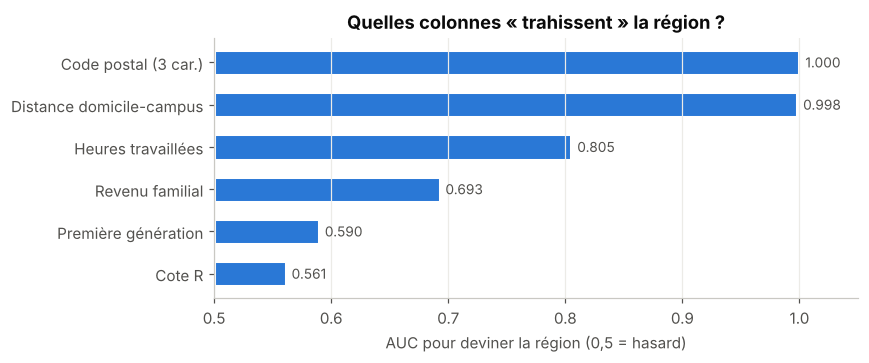

In [8]:
noms = {'code_postal_3': 'Code postal (3 car.)', 'distance_domicile_campus_km': 'Distance domicile-campus',
        'heures_travail_semaine': 'Heures travaillées', 'revenu_familial_estime': 'Revenu familial',
        'premiere_generation_universitaire': 'Première génération', 'cote_r_equivalent': 'Cote R'}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh([noms[i] for i in auc_s.index], auc_s.values - 0.5, left=0.5, height=0.6,
        color=COULEURS['Centre'], edgecolor='white', linewidth=2)
for y, v in enumerate(auc_s.values):
    ax.text(v + 0.005, y, f'{v:.3f}', va='center', fontsize=9, color='#52514e')
ax.axvline(0.5, color=GRIS, lw=1)
ax.set_xlim(0.5, 1.05); ax.grid(axis='y', visible=False)
ax.set_xlabel('AUC pour deviner la région (0,5 = hasard)')
ax.set_title('Quelles colonnes « trahissent » la région ?')
plt.tight_layout(); plt.show()

**Conclusion.** Code postal et distance sont des **proxys parfaits** (le code postal est littéralement la région).
Même sans aucune colonne géographique, heures travaillées + revenu prédisent encore la région avec une AUC ≈ 0,85.
Un modèle entraîné sur `decision_octroi` retrouve donc la pénalité régionale par ces chemins, ce qui explique
pourquoi l'écart de parité ne baisse presque pas quand on retire la région (section 5 du carnet de départ).

## 5. Quelle métrique d'équité ?

| | Parité démographique | Égalité des chances |
|---|---|---|
| Question | Les deux groupes reçoivent-ils autant de bourses ? | Parmi les candidat·es **méritant** la bourse, ont-ils la même chance de l'obtenir ? |
| Besoin | Les décisions seulement | Une définition du mérite |
| Risque | Impose des quotas même si le mérite diffère | Dépend de la qualité de l'étiquette de mérite |

**Choix : égalité des chances.** Une bourse d'excellence récompense le mérite. Exiger des taux identiques
quand les profils diffèrent forcerait à refuser des dossiers méritants d'un groupe pour accepter des dossiers
moins forts de l'autre. L'égalité des chances corrige exactement ce que l'on reproche au comité : refuser des
dossiers méritants à cause de leur région. C'est aussi la métrique de la grille officielle (20 points).

**Le piège :** l'égalité des chances calculée contre `decision_octroi` mesure la fidélité au comité, pas la
justice. Il faut une **estimation du mérite indépendante du comité**.

## 6. Reconstruire le mérite : test contre l'écart publié (0,270)

Les organisateurs indiquent que le modèle de base a un écart d'égalité des chances de **0,270** contre
l'étalon caché. On peut se servir de ce chiffre pour tester des hypothèses sur l'étalon :

1. on reproduit le modèle de base (forêt aléatoire, toutes les colonnes) sur les 4 000 candidat·es ;
2. pour chaque définition candidate du mérite, on construit un étalon (40 % meilleurs scores, avec un bruit
   gaussien d'écart-type 1 point R, 200 tirages) ;
3. on calcule l'écart d'égalité des chances du modèle de base contre cet étalon.

Les poids des variables viennent du modèle logistique D (en points de cote R).

In [9]:
X_hist, X_cand = encoder(hist.drop(columns=['tranche_r', 'eloignee', 'log_revenu']), cand)
base = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42)
base.fit(X_hist, hist.decision_octroi)
pred_base = base.predict(X_cand)
print(f"Modele de base sur les candidats : taux d'octroi {pred_base.mean():.1%}")

w = tableau['equiv. points R']
R = cand.cote_r_equivalent.values
H = cand.heures_travail_semaine.values
LR = np.log(cand.revenu_familial_estime.values)
EL = (cand.groupe == 'Eloignee').values

hypotheses = {
    'cote R seule':                          R,
    'cote R + heures':                       R + w['heures_travail_semaine'] * H,
    'cote R + revenu':                       R + w['log_revenu'] * LR,
    'cote R + heures + revenu':              R + w['heures_travail_semaine'] * H + w['log_revenu'] * LR,
    'comite complet (avec region)':          R + w['heures_travail_semaine'] * H + w['log_revenu'] * LR + w['eloignee'] * EL,
}
rng = np.random.default_rng(0)
lignes = []
for nom, score in hypotheses.items():
    ecarts = [ecart_egalite_chances(top_k(score + rng.normal(0, 1, len(score))), pred_base, cand.groupe)
              for _ in range(200)]
    ref = top_k(score)
    lignes.append({'hypothese de merite': nom,
                   'ecart EO du modele de base': np.mean(ecarts),
                   'ecart-type': np.std(ecarts),
                   'merite Centre': ref[~EL].mean(), 'merite Eloignee': ref[EL].mean()})
test = pd.DataFrame(lignes).set_index('hypothese de merite')
test['distance a 0,270'] = (test['ecart EO du modele de base'] - 0.270).abs()
display(test.round(3).sort_values('distance a 0,270'))

Modele de base sur les candidats : taux d'octroi 39.1%


,ecart EO du modele de base,ecart-type,merite Centre,merite Eloignee,"distance a 0,270"
hypothese de merite,,,,,
cote R + heures,0.266,0.012,0.400,0.400,0.004
cote R + heures + revenu,0.213,0.012,0.422,0.369,0.057
cote R seule,0.192,0.014,0.428,0.359,0.078
cote R + revenu,0.137,0.016,0.452,0.324,0.133
comite complet (avec region),0.017,0.014,0.493,0.265,0.253


**Résultat.** Seule l'hypothèse **« cote R + heures travaillées »** reproduit l'écart publié de 0,270
(à l'incertitude près). Les hypothèses qui gardent le revenu donnent un écart nettement plus petit, et celle qui
garde la région donne un écart nul, ce qui contredit l'audit officiel.

Cette hypothèse est aussi la plus cohérente :

- elle retire les deux canaux biaisés identifiés (région directe, revenu familial) ;
- elle conserve ce que le comité valorise légitimement : la cote R et l'effort de travailler pendant les études ;
- les deux groupes y ont **le même taux de mérite (≈ 40 %)**. La cote R plus basse en région est compensée
  par davantage d'heures travaillées : l'écart de cote R reflète une contrainte de temps, pas un écart de talent.

**Prudence :** c'est une reconstruction, pas l'étalon lui-même. Le niveau de bruit et le poids exact des heures
restent incertains.

**Vérification externe (HxBuddy).** Une soumission « 40 % meilleurs scores cote R + 0,146 × heures » obtient
**94,6 % d'exactitude et 94,4 % de F1 macro contre le mérite réel caché**, contre ≈ 88 % pour un modèle qui imite le comité.
Cette exactitude, combinée à l'écart de 0,270, correspond à un étalon « cote R + 0,11 à 0,15 point par heure »
avec un bruit d'environ 0,5 point R : l'hypothèse tient.

## 6b. Peut-on faire mieux que 94,6 % ? Forme du mérite et plafond

Trois vérifications :

1. **Forme du score.** Des modèles plus flexibles du comité (interaction cote R × heures, spline sur les heures,
   ajout du programme, de la première génération et de la distance) prédisent-ils mieux ses décisions en
   validation croisée ? Si oui, le mérite aurait une forme non linéaire à exploiter.
2. **Sensibilité au poids des heures.** Combien de décisions changent quand ce poids parcourt son intervalle de confiance ?
3. **Taux de mérite de l'étalon.** Les deux scores HxBuddy (exactitude et F1 macro) permettent de retrouver le nombre
   de dossiers méritants dans l'étalon caché, donc de vérifier que 40 % est le bon seuil.

In [10]:
from sklearn.model_selection import StratifiedKFold

hist['R'], hist['H'] = hist.cote_r_equivalent, hist.heures_travail_semaine
SPLINE = 'bs(H, df=4, lower_bound=0, upper_bound=31)'
formes = {
    'lineaire (R, heures, revenu, region)': 'decision_octroi ~ R + H + log_revenu + eloignee',
    '+ interaction R x heures':             'decision_octroi ~ R + H + log_revenu + eloignee + R:H',
    'spline sur les heures':                f'decision_octroi ~ R + {SPLINE} + log_revenu + eloignee',
    '+ programme, 1re gen., distance':      'decision_octroi ~ R + H + log_revenu + eloignee + premiere_generation_universitaire'
                                            ' + distance_domicile_campus_km + C(programme_etudes)',
}
y = hist.decision_octroi.values
proba = {k: np.zeros(len(hist)) for k in formes}
for tr, te in StratifiedKFold(10, shuffle=True, random_state=0).split(hist, y):
    for k, f in formes.items():
        proba[k][te] = smf.logit(f, hist.iloc[tr]).fit(disp=0).predict(hist.iloc[te])
perte = {k: -(y * np.log(p) + (1 - y) * np.log(1 - p)) for k, p in proba.items()}
ref = perte['lineaire (R, heures, revenu, region)']
display(pd.DataFrame({k: {'log-loss (CV 10 plis)': v.mean(),
                          'gain vs lineaire': ref.mean() - v.mean(),
                          'erreur-type du gain': (ref - v).std() / np.sqrt(len(v))}
                      for k, v in perte.items()}).T.round(5))

,log-loss (CV 10 plis),gain vs lineaire,erreur-type du gain
"lineaire (R, heures, revenu, region)",0.25887,0.00000,0.00000
+ interaction R x heures,0.25856,0.00031,0.00027
spline sur les heures,0.25871,0.00016,0.00031
"+ programme, 1re gen., distance",0.25919,-0.00032,0.00025


In [11]:
# Sensibilite : intervalle de confiance du poids des heures (methode delta) et decisions modifiees.
mh = smf.logit('decision_octroi ~ R + H + log_revenu + C(region_administrative)', hist).fit(disp=0)
b, V = mh.params, mh.cov_params()
w_h = b['H'] / b['R']
grad = np.array([1 / b['R'], -b['H'] / b['R'] ** 2])
se = np.sqrt(grad @ V.loc[['H', 'R'], ['H', 'R']].values @ grad)
choix = top_k(R + w_h * H)
for w_test in [w_h - 1.96 * se, w_h + 1.96 * se]:
    print(f'poids {w_test:.3f} : {int((top_k(R + w_test * H) != choix).sum())} decisions sur 4000 changent')
print(f'poids des heures = {w_h:.4f} (IC 95 % : {w_h - 1.96 * se:.3f} a {w_h + 1.96 * se:.3f})')

poids 0.130 : 24 decisions sur 4000 changent
poids 0.161 : 18 decisions sur 4000 changent
poids des heures = 0.1454 (IC 95 % : 0.130 a 0.161)


In [12]:
# Taux de merite de l'etalon cache, retrouve a partir des deux scores HxBuddy de la soumission a 40 %.
N, P = 4000, 1600
erreurs = round(N * (1 - 0.9463))                  # exactitude affichee 94,63 % -> 215 erreurs
compatibles = []
for Q in range(1400, 1801):                        # Q = nombre de dossiers meritants dans l'etalon
    if (erreurs + Q - P) % 2:
        continue
    fp, fn = (erreurs - (Q - P)) // 2, (erreurs + (Q - P)) // 2
    vp, vn = P - fp, N - P - fn
    f1_macro = (2 * vp / (P + Q) + 2 * vn / (2 * N - P - Q)) / 2
    if round(100 * f1_macro, 2) == 94.40:           # F1 macro affiche 94,4 %
        compatibles.append(Q)
print(f'{erreurs} erreurs ; nombre de meritants compatible avec le F1 : {min(compatibles)} a {max(compatibles)} '
      f'({min(compatibles) / N:.1%} a {max(compatibles) / N:.1%})')

215 erreurs ; nombre de meritants compatible avec le F1 : 1591 a 1605 (39.8% a 40.1%)


**Conclusion : on est au plafond.**

- Aucune forme plus flexible ne prédit nettement mieux le comité : les gains de log-loss restent de l'ordre de
  leur erreur-type (au plus 1,2 erreur-type).
  Le comité, donc le mérite qu'il contient, est linéaire en cote R et en heures. Ajouter le programme, la première
  génération et la distance dégrade même la prédiction. On les retire donc du score : c'est plus parcimonieux, et
  cela évite de pénaliser (même légèrement) les étudiant·es de première génération. HxBuddy le confirme : 94,63 %
  sans ces variables, 94,58 % avec.
- Déplacer le poids des heures dans tout son intervalle de confiance ne change qu'une vingtaine de décisions sur 4 000.
- L'étalon contient environ 40 % de dossiers méritants, comme notre sélection : le seuil est le bon.

Les ≈ 5 % d'erreurs restantes viennent d'une variation aléatoire de l'étalon qu'aucune colonne ne contient.
Le plafond réaliste est d'environ 95 %. Chercher à le dépasser en multipliant les soumissions reviendrait à
ajuster le modèle au score indicatif plutôt qu'au mérite.

## 7. Audit du modèle de base contre le mérite reconstruit

In [13]:
merite = top_k(hypotheses['cote R + heures'])

def audit(pred, nom):
    g = cand.groupe.values
    r = {'modele': nom, 'taux octroi': pred.mean(),
         'exactitude vs merite': (pred == merite).mean()}
    for grp in ('Centre', 'Eloignee'):
        r[f'TPR {grp}'] = pred[(g == grp) & (merite == 1)].mean()
        r[f'FPR {grp}'] = pred[(g == grp) & (merite == 0)].mean()
    r['ecart egalite chances'] = ecart_egalite_chances(merite, pred, g)
    r['ecart parite'] = ecart_parite(pred, g)
    return r

display(pd.DataFrame([audit(pred_base, 'foret de base (production)')]).set_index('modele').round(3).T)

modele,foret de base (production)
taux octroi,0.390
exactitude vs merite,0.903
TPR Centre,0.987
FPR Centre,0.122
TPR Eloignee,0.691
FPR Eloignee,0.002
ecart egalite chances,0.296
ecart parite,0.190


Parmi les candidat·es qui méritent la bourse, le modèle de base en refuse **≈ 31 % en région éloignée contre ≈ 1 %
au Centre**. Il accorde aussi des bourses à des dossiers du Centre qui ne les méritent pas (FPR plus élevé).
Les 88 % d'exactitude du tableau de bord cachent cette asymétrie.

## 8. Limites du diagnostic

- **Données synthétiques.** Les relations sont plus nettes qu'en réalité (effets linéaires, pas d'interactions).
- **Le mérite reste une hypothèse.** Il est reconstruit à partir du comportement du comité et d'un seul chiffre
  publié. Si l'étalon caché valorise le revenu ou d'autres critères, nos corrections seraient trop fortes.
- **Deux groupes seulement.** On regroupe 5 régions en 2 blocs, comme l'audit officiel. Les écarts entre
  Bas-Saint-Laurent, Côte-Nord et Gaspésie sont faibles, mais un suivi par région reste nécessaire.
- **Intersectionnalité non traitée.** Première génération × région, ou programme × région, mériteraient un
  audit séparé avec plus de données.
- **Variable « heures travaillées ».** Elle est fortement liée à la région (AUC ≈ 0,8). La garder comme critère de
  mérite est un choix de valeurs défendable, mais il doit être explicité devant un comité d'éthique.